In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("Data/IMDB Dataset.csv")
if not data_path.is_file():
    data_path = Path("../Data/IMDB Dataset.csv")

df = pd.read_csv(data_path)

print("Shape:", df.shape)
df.head()


Shape: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [2]:
print("Missing values:")
print(df[["review", "sentiment"]].isna().sum())

print("\nSentiment counts:")
print(df["sentiment"].value_counts())

duplicate_count = df.duplicated(subset="review").sum()
print("\nRepeated reviews:", duplicate_count)

label_counts = df.groupby("review")["sentiment"].nunique()
conflicting_reviews = label_counts[label_counts > 1].index

print("Reviews with conflicting labels:", len(conflicting_reviews))

df = df.dropna(subset=["review", "sentiment"]).copy()

df = df[~df["review"].isin(conflicting_reviews)].copy()
df = df.drop_duplicates(subset="review").reset_index(drop=True)

print("\nShape after cleaning:", df.shape)
print("\nClass balance after cleaning:")
print(df["sentiment"].value_counts())

Missing values:
review       0
sentiment    0
dtype: int64

Sentiment counts:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Repeated reviews: 418
Reviews with conflicting labels: 0

Shape after cleaning: (49582, 2)

Class balance after cleaning:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


In [3]:
from sklearn.model_selection import train_test_split

df['label'] = df['sentiment'].map({
    "negative" : 0,
    "positive" : 1
})

train_df , remaining_df = train_test_split(df , test_size = 0.30 , random_state = 42 , stratify = df['label'])


In [4]:
valid_df , test_df = train_test_split(remaining_df , test_size = 0.5 , random_state = 42 , stratify = remaining_df['label'])

In [5]:
import re
import html

def clean_review(text):
    text = html.unescape(text)

    text = re.sub(r"<[^>]+>", " ", text)

    text = text.lower()

    text = re.sub(r"\s+", " ", text).strip()

    return text

train_df = train_df.copy()
valid_df = valid_df.copy()
test_df = test_df.copy()

for split in [train_df, valid_df, test_df]:
    split["clean_review"] = split["review"].apply(clean_review)


for name, split in [
    ("Train", train_df),
    ("Validation", valid_df),
    ("Test", test_df)
]:
    empty_count = split["clean_review"].eq("").sum()
    print(f"{name} empty reviews: {empty_count}")

Train empty reviews: 0
Validation empty reviews: 0
Test empty reviews: 0


In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer

max_vocab_size = 20_000

tokenizer = Tokenizer(num_words = max_vocab_size , oov_token = '<OOV>')
tokenizer.fit_on_texts(train_df['clean_review'])

train_sequences = tokenizer.texts_to_sequences(train_df["clean_review"])
valid_sequences = tokenizer.texts_to_sequences(valid_df["clean_review"])
test_sequences = tokenizer.texts_to_sequences(test_df["clean_review"])

vocab_size = min(
    max_vocab_size,
    len(tokenizer.word_index) + 1
)


print("Unique words found:", len(tokenizer.word_index))
print("Embedding vocabulary size:", vocab_size)
print("OOV token ID:", tokenizer.word_index["<OOV>"])

print("\nReview:")
print(train_df["clean_review"].iloc[0][:300])

print("\nFirst 30 token IDs:")
print(train_sequences[0][:30])

print("\nTheir corresponding words:")
print([
    tokenizer.index_word[token_id]
    for token_id in train_sequences[0][:30]
])

Unique words found: 104988
Embedding vocabulary size: 20000
OOV token ID: 1

Review:
i work in a library and expected to like this movie when it came out 5 years ago. well i liked parker posey a lot (she's a wonderful actress) and omar townsend was really cute as her boyfriend (he couldn't act but when you look like him who cares?) but the movie was bad. it wasn't funny or cute or m

First 30 token IDs:
[10, 160, 8, 4, 3354, 3, 851, 6, 37, 11, 15, 51, 9, 382, 42, 453, 152, 618, 70, 10, 431, 2487, 8463, 4, 168, 458, 4, 395, 543, 3]

Their corresponding words:
['i', 'work', 'in', 'a', 'library', 'and', 'expected', 'to', 'like', 'this', 'movie', 'when', 'it', 'came', 'out', '5', 'years', 'ago', 'well', 'i', 'liked', 'parker', 'posey', 'a', 'lot', "she's", 'a', 'wonderful', 'actress', 'and']


In [7]:
import numpy as np
train_lengths = np.array([
    len(sequence) for sequence in train_sequences
])

print("Shortest review:", train_lengths.min())
print("Longest review:", train_lengths.max())
for percentile in [50, 75, 90, 95]:
    length = np.percentile(train_lengths, percentile)
    print(f"{percentile}th percentile: {length:.0f} tokens")

for length in [200, 300, 400, 500]:
    truncated_percent = (train_lengths > length).mean() * 100

    print(
        f"Length {length}: "
        f"{truncated_percent:.1f}% of training reviews would be truncated"
    )

Shortest review: 6
Longest review: 2473
50th percentile: 174 tokens
75th percentile: 282 tokens
90th percentile: 450 tokens
95th percentile: 588 tokens
Length 200: 41.0% of training reviews would be truncated
Length 300: 22.3% of training reviews would be truncated
Length 400: 12.8% of training reviews would be truncated
Length 500: 7.7% of training reviews would be truncated


In [8]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

sequence_length = 300

X_train = pad_sequences(
    train_sequences,
    maxlen=sequence_length,
    padding="post",
    truncating="post"
)

X_valid = pad_sequences(
    valid_sequences,
    maxlen=sequence_length,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    test_sequences,
    maxlen=sequence_length,
    padding="post",
    truncating="post"
)

y_train = train_df["label"].to_numpy(dtype="int32")
y_valid = valid_df["label"].to_numpy(dtype="int32")
y_test = test_df["label"].to_numpy(dtype="int32")

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_valid.shape, y_valid.shape)
print("Test:", X_test.shape, y_test.shape)

print(
    "\nTraining reviews truncated:",
    f"{(train_lengths > sequence_length).mean():.1%}"
)

Training: (34707, 300) (34707,)
Validation: (7437, 300) (7437,)
Test: (7438, 300) (7438,)

Training reviews truncated: 22.3%


In [9]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input , Embedding , GRU , Dense

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape = (sequence_length,) , dtype = 'int32'),
    Embedding(input_dim = vocab_size , output_dim = 100 , mask_zero = True),
    GRU(64),
    Dense(1, activation = 'sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 300, 100)       │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        31,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,031,937 (7.75 MB)

 Trainable params: 2,031,937 (7.75 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.AUC(name="roc_auc")
    ]
)

In [11]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_valid, y_valid),
    epochs=10,          
    batch_size=64,      
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10
543/543 ━━━━━━━━━━━━━━━━━━━━ 136s 243ms/step - accuracy: 0.8105 - loss: 0.4042 - roc_auc: 0.8975 - val_accuracy: 0.8803 - val_loss: 0.2920 - val_roc_auc: 0.9487
Epoch 2/10
543/543 ━━━━━━━━━━━━━━━━━━━━ 136s 251ms/step - accuracy: 0.9155 - loss: 0.2225 - roc_auc: 0.9689 - val_accuracy: 0.8581 - val_loss: 0.3573 - val_roc_auc: 0.9475
Epoch 3/10
543/543 ━━━━━━━━━━━━━━━━━━━━ 135s 248ms/step - accuracy: 0.9415 - loss: 0.1598 - roc_auc: 0.9832 - val_accuracy: 0.8756 - val_loss: 0.3306 - val_roc_auc: 0.9473


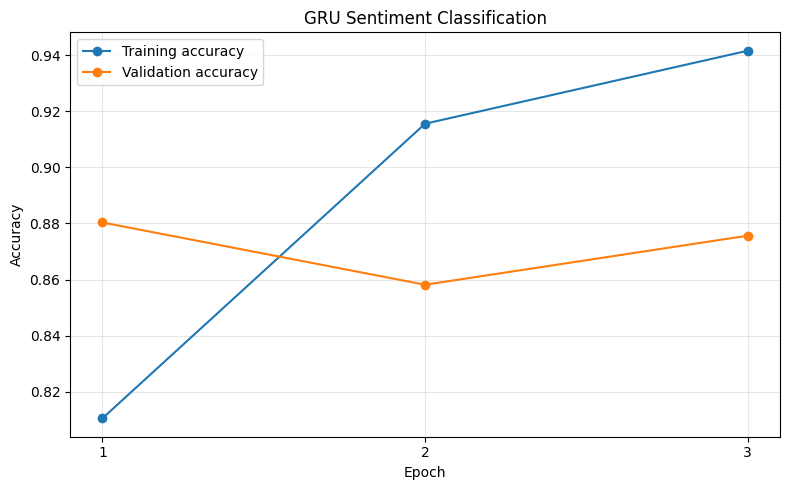

In [12]:
import matplotlib.pyplot as plt

train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]

epochs = range(1, len(train_accuracy) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, train_accuracy, marker="o", label="Training accuracy")
plt.plot(epochs, val_accuracy, marker="o", label="Validation accuracy")

plt.title("GRU Sentiment Classification")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
from sklearn.metrics import classification_report, confusion_matrix

test_results = model.evaluate(
    X_test,
    y_test,
    batch_size=64,
    verbose=0,
    return_dict=True
)

print("Test metrics:")
for name, value in test_results.items():
    print(f"{name}: {value:.4f}")
test_probabilities = model.predict(
    X_test,
    batch_size=64,
    verbose=0
).ravel()

test_predictions = (test_probabilities >= 0.5).astype("int32")

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, test_predictions, labels=[0, 1]))

Test metrics:
accuracy: 0.8790
loss: 0.2946
roc_auc: 0.9486

Classification report:
              precision    recall  f1-score   support

    Negative     0.9020    0.8494    0.8749      3705
    Positive     0.8587    0.9084    0.8828      3733

    accuracy                         0.8790      7438
   macro avg     0.8803    0.8789    0.8789      7438
weighted avg     0.8803    0.8790    0.8789      7438

Confusion matrix:
[[3147  558]
 [ 342 3391]]


In [25]:
review = "The movie was cool"
cleaned = clean_review(review)
tokens = tokenizer.texts_to_sequences([cleaned])
padded = pad_sequences(
    tokens,
    maxlen=sequence_length,
    padding="post",
    truncating="post"
)
positive_probability = float(model.predict(padded, verbose=0)[0, 0])
sentiment = "Positive" if positive_probability >= 0.5 else "Negative"

print("Review:", review)
print("Predicted sentiment:", sentiment)
print(f"Positive probability: {positive_probability:.2%}")

Review: The movie was cool
Predicted sentiment: Positive
Positive probability: 54.86%
